# DeepCare 06: Explainability and subgroup analysis (Keras MLP)

The MLP is the project's main model, so this notebook explains and audits it.

1. **SHAP** feature attributions for the MLP. The explained quantity is the **calibrated risk** (Platt-scaled), so attributions are in the same units the demo app will show.
2. **Cross-check** against XGBoost's exact TreeSHAP: if two quite different models rank features similarly, the importance story is more trustworthy.
3. **Local explanations** for individual people (the same view the app will offer).
4. **Subgroup performance** by sex, age band and income band at the 80% recall operating point: recall, precision, and whether predicted risk matches the observed rate within each group.
5. **App configuration** saved for the demo (feature order, ranges, thresholds).

Caveats to carry into the report: SHAP describes what the *model* relies on, not what *causes* diabetes, and Kernel SHAP values are Monte-Carlo estimates computed on a sample of test rows.

## 1. Setup and load

In [1]:
!pip -q install shap

In [2]:
import os, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import xgboost as xgb
import shap
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, confusion_matrix
from google.colab import drive
drive.mount('/content/drive')

SEED = 42
N_EXPLAIN = 400        # test rows to explain (Kernel SHAP is the slow part; lower if needed)
N_BACKGROUND = 50      # k-means background summary size
N_SAMPLES = 500        # Kernel SHAP coalition samples per row
PROJECT_DIR = '/content/drive/MyDrive/deepcare'
D, R, M = f'{PROJECT_DIR}/data', f'{PROJECT_DIR}/results', f'{PROJECT_DIR}/models'
TARGET = 'Diabetes_binary'

def load(split, kind):
    df = pd.read_csv(f'{D}/{split}_{kind}.csv')
    return df.drop(columns=[TARGET]), df[TARGET].to_numpy().astype(int)

Xtr_s, ytr = load('train', 'scaled'); Xte_s, yte = load('test', 'scaled')
Xtr_r, _ = load('train', 'raw');      Xte_r, _ = load('test', 'raw')
cols = list(Xte_s.columns)

model = tf.keras.models.load_model(f'{M}/mlp.keras')
platt = joblib.load(f'{R}/calibrators.joblib')['mlp']['platt']
z = np.load(f'{R}/probs_mlp.npz')
p_val_raw, p_raw = z['val'], z['test']
yva = z['val_y'].astype(int)

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

# sanity check: the reloaded model must reproduce the saved test probabilities
p_chk = model.predict(Xte_s.to_numpy('float32'), batch_size=8192, verbose=0).ravel()
print('max |reloaded - saved| test probability:', float(np.abs(p_chk - p_raw).max()))
p_cal = platt.predict_proba(logit(p_raw))[:, 1]
print('test rows:', len(yte), '| mean calibrated risk:', round(float(p_cal.mean()), 4), '| observed rate:', round(float(yte.mean()), 4))

Mounted at /content/drive
max |reloaded - saved| test probability: 1.1920928955078125e-07
test rows: 34422 | mean calibrated risk: 0.1532 | observed rate: 0.153


## 2. SHAP for the MLP

Kernel SHAP is model-agnostic and works with the calibrated risk function. A k-means summary of training rows serves as the background distribution.

In [3]:
rng = np.random.default_rng(SEED)
bg_idx = rng.choice(len(Xtr_s), 5000, replace=False)
background = shap.kmeans(Xtr_s.to_numpy('float32')[bg_idx], N_BACKGROUND)

def f_cal(x):
    p = model.predict(np.asarray(x, dtype='float32'), batch_size=8192, verbose=0).ravel()
    return platt.predict_proba(logit(p))[:, 1]

explainer = shap.KernelExplainer(f_cal, background)
ex_idx = rng.choice(len(Xte_s), N_EXPLAIN, replace=False)
Xs_ex = Xte_s.to_numpy('float32')[ex_idx]
Xr_ex = Xte_r.to_numpy()[ex_idx]

sv = np.array(explainer.shap_values(Xs_ex, nsamples=N_SAMPLES, silent=True))
if sv.ndim == 3:
    sv = sv[..., 0]
base_value = float(np.ravel(explainer.expected_value)[0])

# additivity check: base value + sum of attributions should reproduce each prediction (up to Monte-Carlo error)
err = np.abs(base_value + sv.sum(1) - f_cal(Xs_ex))
print(f'base value (average calibrated risk): {base_value:.4f} | additivity error: mean {err.mean():.4f}, max {err.max():.4f}')

imp_mlp = pd.Series(np.abs(sv).mean(0), index=cols).sort_values(ascending=False)
imp_mlp.to_csv(f'{R}/shap_importance_mlp.csv', header=['mean_abs_shap'])
display(imp_mlp.round(4).head(10))

base value (average calibrated risk): 0.1627 | additivity error: mean 0.0000, max 0.0000


,0
GenHlth,0.0481
BMI,0.0412
HighBP,0.0350
HighChol,0.0284
Age,0.0275
Sex,0.0115
Income,0.0092
HeartDiseaseorAttack,0.0047
MentHlth,0.0036
DiffWalk,0.0034


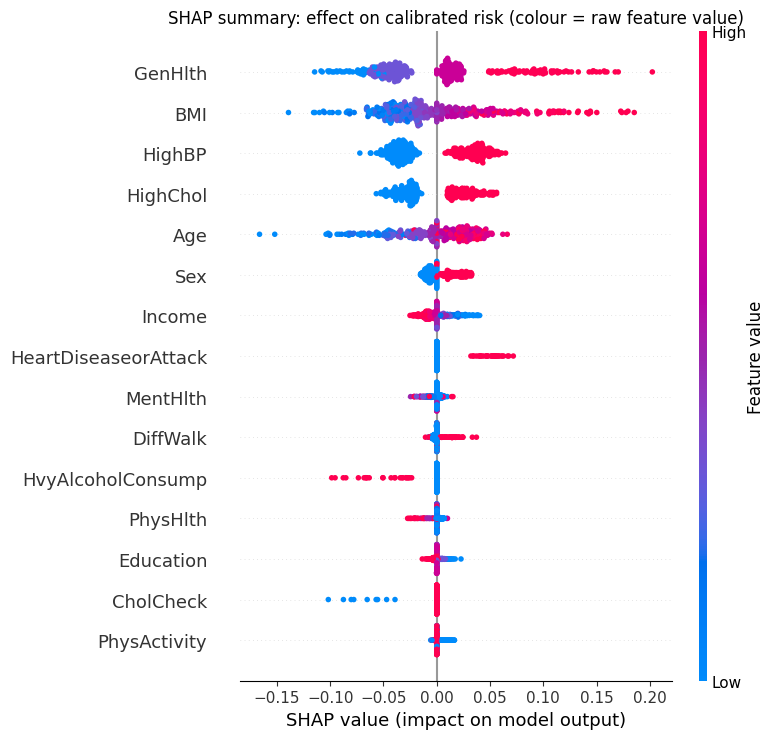

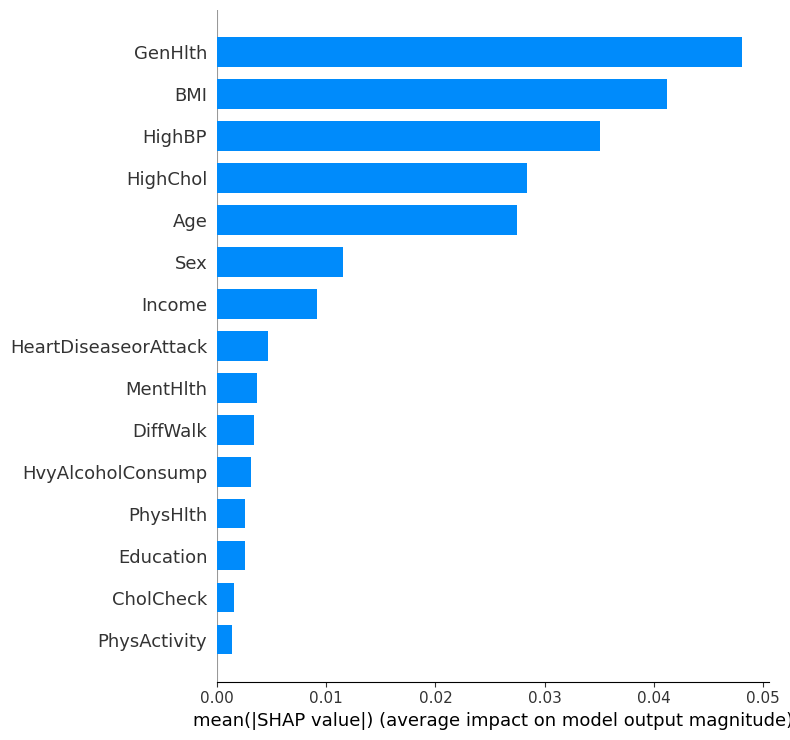

In [4]:
plt.figure()
shap.summary_plot(sv, Xr_ex, feature_names=cols, show=False, max_display=15)
plt.title('SHAP summary: effect on calibrated risk (colour = raw feature value)')
plt.tight_layout(); plt.savefig(f'{R}/shap_summary_mlp.png', dpi=150, bbox_inches='tight'); plt.show()

plt.figure()
shap.summary_plot(sv, Xr_ex, feature_names=cols, plot_type='bar', show=False, max_display=15)
plt.tight_layout(); plt.savefig(f'{R}/shap_bar_mlp.png', dpi=150, bbox_inches='tight'); plt.show()

## 3. Cross-check with XGBoost (TreeSHAP) and dependence of the top features

XGBoost attributions are in log-odds units and the MLP's in calibrated-probability units, so only the **ranking** is comparable.

In [5]:
xg = xgb.XGBClassifier()
xg.load_model(f'{M}/xgboost.json')
sv_x = shap.TreeExplainer(xg).shap_values(Xte_r.iloc[ex_idx])
imp_xgb = pd.Series(np.abs(sv_x).mean(0), index=cols)

cmp = pd.DataFrame({'mlp_rank': imp_mlp.rank(ascending=False).astype(int),
                    'xgb_rank': imp_xgb.rank(ascending=False).astype(int)}).sort_values('mlp_rank')
rho = spearmanr(imp_mlp[cols], imp_xgb[cols]).correlation
print(f'Spearman rank correlation of mean |SHAP| (MLP vs XGBoost): {rho:.3f}')
display(cmp.head(10))
cmp.to_csv(f'{R}/shap_rank_comparison.csv')

Spearman rank correlation of mean |SHAP| (MLP vs XGBoost): 0.945


,mlp_rank,xgb_rank
GenHlth,1,1
BMI,2,3
HighBP,3,2
HighChol,4,5
Age,5,4
Sex,6,6
Income,7,7
HeartDiseaseorAttack,8,10
MentHlth,9,8
DiffWalk,10,11


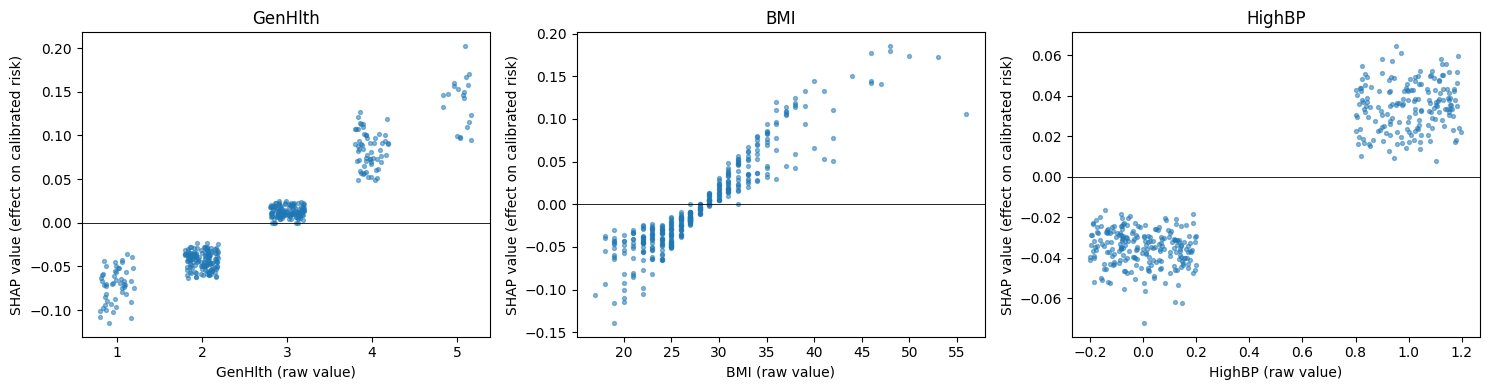

In [6]:
top3 = list(imp_mlp.index[:3])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, f in zip(ax, top3):
    j = cols.index(f)
    x = Xr_ex[:, j].astype(float)
    if len(np.unique(x)) <= 15:
        x = x + rng.uniform(-0.2, 0.2, len(x))
    a.scatter(x, sv[:, j], s=8, alpha=0.5)
    a.axhline(0, color='k', lw=0.6)
    a.set(title=f, xlabel=f'{f} (raw value)', ylabel='SHAP value (effect on calibrated risk)')
plt.tight_layout(); plt.savefig(f'{R}/shap_dependence_top3.png', dpi=150); plt.show()

## 4. Local explanations

One high-risk and one typical person from the explained sample: how each feature moves the predicted risk away from the average.

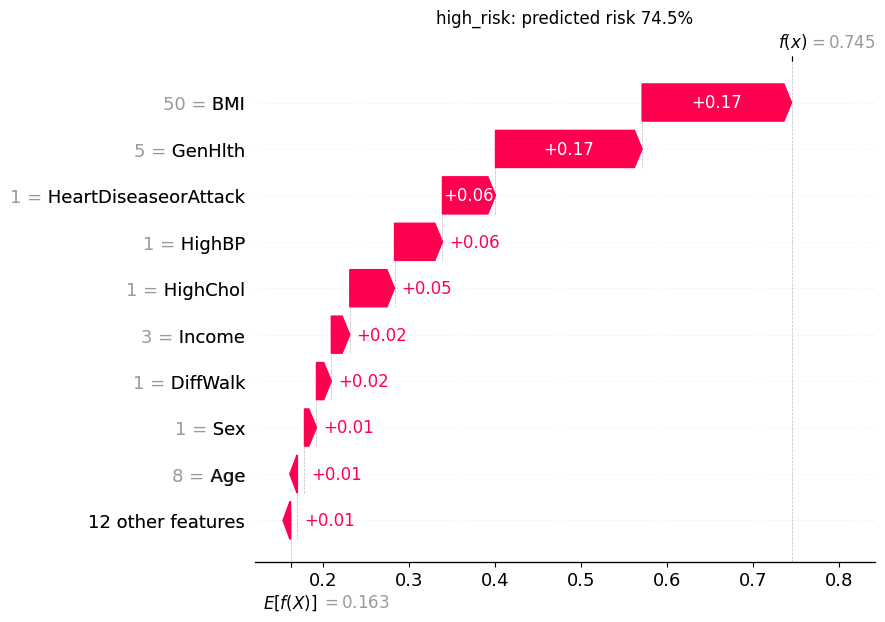

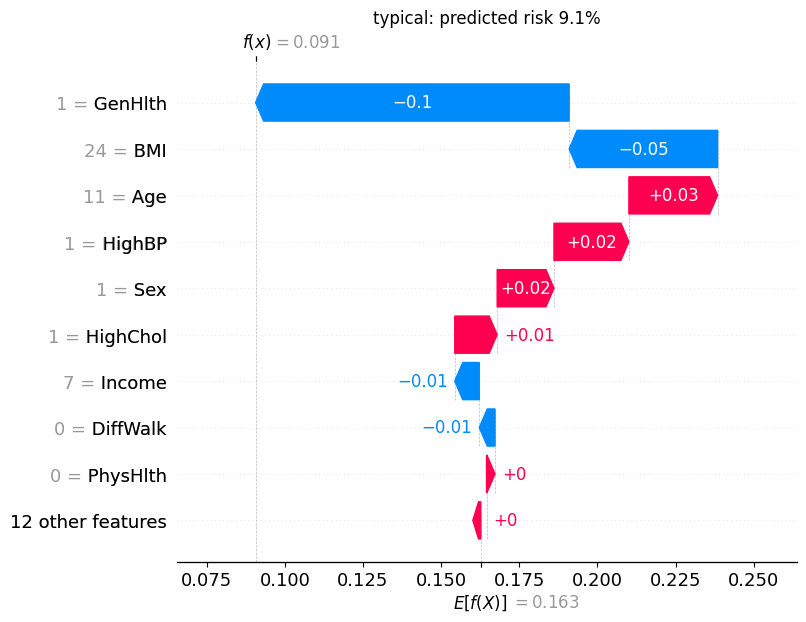

In [7]:
p_ex = f_cal(Xs_ex)
picks = {'high_risk': int(np.argmax(p_ex)), 'typical': int(np.argmin(np.abs(p_ex - np.median(p_ex))))}
for name, i in picks.items():
    exp = shap.Explanation(values=sv[i], base_values=base_value, data=Xr_ex[i], feature_names=cols)
    plt.figure()
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.title(f'{name}: predicted risk {p_ex[i]:.1%}')
    plt.savefig(f'{R}/shap_waterfall_{name}.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Subgroup performance at the 80% recall operating point

The threshold is the one chosen on the **validation** set for 80% recall (same as notebook 05). Per group we report discrimination, recall, precision, and whether mean predicted risk matches the observed rate.

Reading guide: precision depends on prevalence, so groups with different base rates will differ in precision even for an equally good model. The most telling columns are `recall` (are cases caught equally often?) and `mean_calibrated_risk` vs `observed_rate`. The `Sex` column is shown as 0/1; check the UCI codebook for the coding. Age and income are ordinal category codes.

In [8]:
def threshold_for_recall(y, p, target):
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= target)[0]
    return float(thr[ok[-1]]) if len(ok) else float(thr[0])

THR80 = threshold_for_recall(yva, p_val_raw, 0.80)
print('threshold for 80% validation recall (raw MLP score):', round(THR80, 4))

def group_metrics(mask, label):
    y, pr, pc = yte[mask], p_raw[mask], p_cal[mask]
    pred = (pr >= THR80).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    pos = tp + fn
    rec = tp / pos if pos else np.nan
    ok = 0 < y.mean() < 1
    return {'group': label, 'n': int(mask.sum()), 'positives': int(pos), 'observed_rate': y.mean(),
            'mean_calibrated_risk': pc.mean(),
            'roc_auc': roc_auc_score(y, pr) if ok else np.nan,
            'pr_auc': average_precision_score(y, pr) if ok else np.nan,
            'recall': rec, 'recall_ci95': 1.96 * np.sqrt(rec * (1 - rec) / pos) if pos else np.nan,
            'precision': tp / (tp + fp) if (tp + fp) else np.nan,
            'specificity': tn / (tn + fp) if (tn + fp) else np.nan,
            'flagged_share': (tp + fp) / len(y)}

def by_bands(col, bands):
    v = Xte_r[col].to_numpy()
    return [group_metrics((v >= lo) & (v <= hi), f'{col} {lo}-{hi}') for lo, hi in bands.values()]

rows = [group_metrics(np.ones(len(yte), bool), 'ALL')]
rows += [group_metrics(Xte_r['Sex'].to_numpy() == s, f'Sex={s}') for s in sorted(Xte_r['Sex'].unique())]
rows += by_bands('Age', {'a': (1, 3), 'b': (4, 6), 'c': (7, 9), 'd': (10, 11), 'e': (12, 13)})
rows += by_bands('Income', {'a': (1, 3), 'b': (4, 6), 'c': (7, 8)})
sub = pd.DataFrame(rows).set_index('group')
display(sub.round(3))
sub.to_csv(f'{R}/subgroup_performance_mlp.csv')

threshold for 80% validation recall (raw MLP score): 0.507


,n,positives,observed_rate,mean_calibrated_risk,roc_auc,pr_auc,recall,recall_ci95,precision,specificity,flagged_share
group,,,,,,,,,,,
ALL,34422,5265,0.153,0.153,0.818,0.438,0.799,0.011,0.316,0.687,0.387
Sex=0,19235,2749,0.143,0.142,0.827,0.429,0.781,0.015,0.320,0.723,0.349
Sex=1,15187,2516,0.166,0.167,0.806,0.448,0.819,0.015,0.312,0.641,0.435
Age 1-3,3348,81,0.024,0.021,0.853,0.194,0.309,0.101,0.321,0.984,0.023
Age 4-6,6457,506,0.078,0.074,0.826,0.333,0.545,0.043,0.294,0.889,0.145
Age 7-9,11956,1984,0.166,0.167,0.818,0.469,0.803,0.018,0.334,0.681,0.399
Age 10-11,7727,1706,0.221,0.220,0.766,0.460,0.863,0.016,0.331,0.507,0.575
Age 12-13,4934,988,0.200,0.209,0.721,0.395,0.850,0.022,0.272,0.430,0.626
Income 1-3,5718,1380,0.241,0.240,0.774,0.500,0.891,0.016,0.360,0.496,0.597


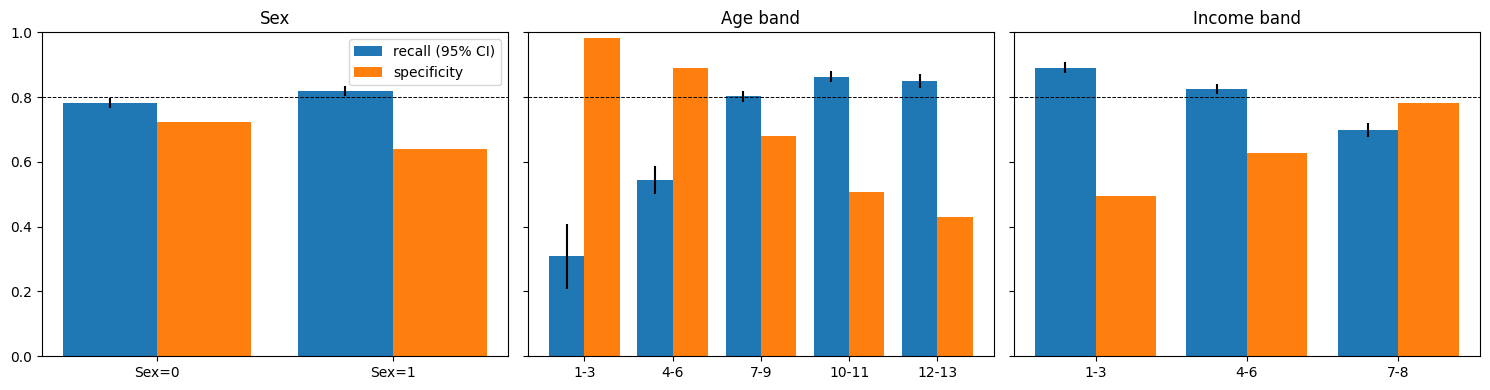

In [9]:
fams = {'Sex': [g for g in sub.index if g.startswith('Sex')],
        'Age band': [g for g in sub.index if g.startswith('Age')],
        'Income band': [g for g in sub.index if g.startswith('Income')]}
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, (fam, groups) in zip(ax, fams.items()):
    s = sub.loc[groups]
    x = np.arange(len(groups))
    a.bar(x - 0.2, s['recall'], 0.4, yerr=s['recall_ci95'], label='recall (95% CI)')
    a.bar(x + 0.2, s['specificity'], 0.4, label='specificity')
    a.axhline(0.8, color='k', ls='--', lw=0.7)
    a.set_xticks(x); a.set_xticklabels([g.split(' ', 1)[-1] if ' ' in g else g for g in groups], rotation=0)
    a.set_title(fam)
ax[0].legend(); ax[0].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(f'{R}/subgroup_recall_specificity.png', dpi=150); plt.show()

## 6. Save the app configuration

Everything the demo needs besides the model, scaler and calibrator: feature order, input ranges, BMI clipping, the 80%-recall threshold (raw and calibrated), and the dataset prevalence used for calibration.

In [10]:
prep = json.load(open(f'{PROJECT_DIR}/prep_config.json'))
cfg = {
    'feature_order': cols,
    'NUM': prep['NUM'], 'BIN': prep['BIN'], 'bmi_clip': prep['bmi_clip'],
    'feature_ranges': {c: [float(Xtr_r[c].min()), float(Xtr_r[c].max())] for c in cols},
    'threshold_recall80_raw': THR80,
    'threshold_recall80_calibrated': float(platt.predict_proba(logit(np.array([THR80])))[:, 1][0]),
    'dataset_prevalence': float(ytr.mean()),
    'calibration': 'platt (fitted on validation set)',
    'shap_base_value': base_value,
}
json.dump(cfg, open(f'{M}/app_config.json', 'w'), indent=2)
print(json.dumps({k: v for k, v in cfg.items() if k not in ('feature_ranges',)}, indent=2))

{
  "feature_order": [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex",
    "BMI",
    "MentHlth",
    "PhysHlth",
    "GenHlth",
    "Age",
    "Education",
    "Income"
  ],
  "NUM": [
    "BMI",
    "MentHlth",
    "PhysHlth",
    "GenHlth",
    "Age",
    "Education",
    "Income"
  ],
  "BIN": [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex"
  ],
  "bmi_clip": [
    17.0,
    56.0
  ],
  "threshold_recall80_raw": 0.5070404410362244,
  "threshold_recall80_calibrated": 0.1496313452840251,
  "dataset_prevalence": 0.152946815994422,
  "calibration": "platt (fitted on validation set)",
  "shap_base_val